In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Load dataset

df = pd.read_csv("C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv")

# Create binary target

df_model = df.copy()

df_model["target"] = (df_model["num"] > 0).astype(int)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df_model["target"].value_counts())

Dataset loaded successfully.
Dataset shape: (900, 77)

Target distribution:
target
1    496
0    404
Name: count, dtype: int64


In [4]:
# Select clinically relevant features

selected_features = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

X = df_model[selected_features].copy()
y = df_model["target"].copy()

# Handle remaining missing values

for column in X.columns:
    if X[column].isnull().sum() > 0:
        X[column] = X[column].fillna(X[column].median())

print("Selected features:", len(selected_features))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features: 13
Feature matrix shape: (900, 13)
Target shape: (900,)


In [5]:
# Select clinically relevant features

selected_features = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

X = df_model[selected_features].copy()
y = df_model["target"].copy()

# Handle remaining missing values

for column in X.columns:
    if X[column].isnull().sum() > 0:
        X[column] = X[column].fillna(X[column].median())

print("Selected features:", len(selected_features))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features: 13
Feature matrix shape: (900, 13)
Target shape: (900,)


In [6]:
# Stratified 80:20 train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (720, 13)
Testing data : (180, 13)

Training class distribution:
target
1    397
0    323
Name: count, dtype: int64

Testing class distribution:
target
1    99
0    81
Name: count, dtype: int64


In [7]:
# Create SVM pipeline

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

print("SVM pipeline created successfully.")

print("\nModel configuration:")
print("Kernel: RBF")
print("C: 1.0")
print("Gamma: scale")

SVM pipeline created successfully.

Model configuration:
Kernel: RBF
C: 1.0
Gamma: scale


In [8]:
# Train the SVM model

svm_model.fit(X_train, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


In [9]:
# Generate predictions

y_pred = svm_model.predict(X_test)

# Generate probability predictions

y_prob = svm_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(np.round(y_prob[:10], 4))

Predictions generated successfully.

First 10 predicted classes:
[1 0 1 1 0 1 0 0 1 1]

First 10 predicted probabilities:
[0.5679 0.0877 0.8764 0.8735 0.1243 0.8584 0.1153 0.4627 0.6575 0.8686]


In [10]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

svm_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(svm_results.round(4))

,Metric,Score
0,Accuracy,0.8278
1,Precision,0.8148
2,Recall,0.8889
3,F1 Score,0.8502
4,ROC-AUC,0.9108


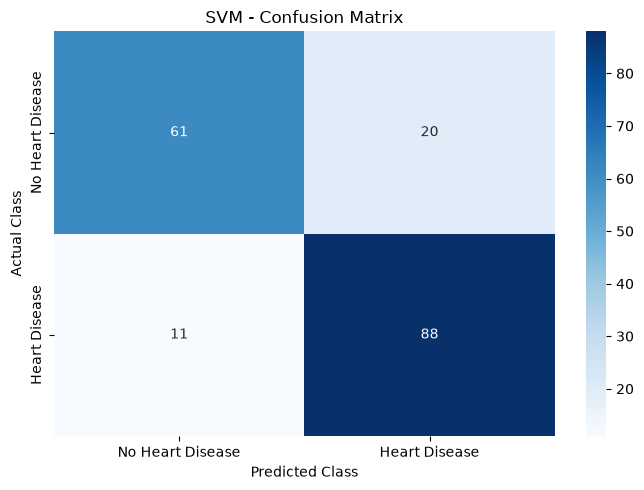


Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.85      0.75      0.80        81
   Heart Disease       0.81      0.89      0.85        99

        accuracy                           0.83       180
       macro avg       0.83      0.82      0.82       180
    weighted avg       0.83      0.83      0.83       180



In [11]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Heart Disease",
        "Heart Disease"
    ],
    yticklabels=[
        "No Heart Disease",
        "Heart Disease"
    ]
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


# Classification Report

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ],
        zero_division=0
    )
)

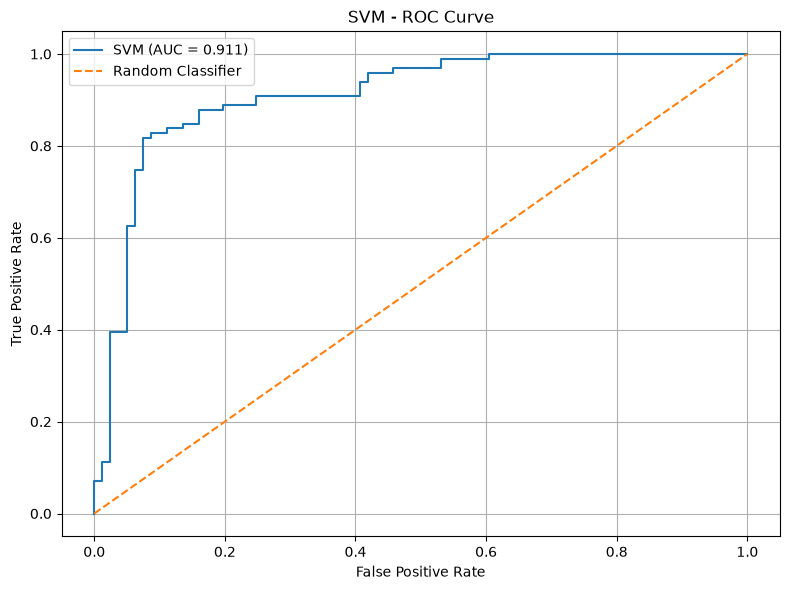

In [12]:
# Generate ROC curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"SVM (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("SVM - ROC Curve")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [13]:
# Perform 5-fold stratified cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("SVM 5-Fold Cross-Validation")
print("===========================")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV Accuracy:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

SVM 5-Fold Cross-Validation
Fold 1: 0.7569
Fold 2: 0.7847
Fold 3: 0.7986
Fold 4: 0.8194
Fold 5: 0.8264

Mean CV Accuracy: 0.7972
Standard Deviation: 0.025


In [14]:
# Analyze incorrect predictions

prediction_analysis = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Probability": y_prob
})

prediction_analysis["Correct"] = (
    prediction_analysis["Actual"] ==
    prediction_analysis["Predicted"]
)

incorrect = prediction_analysis[
    prediction_analysis["Correct"] == False
]

print("Total test observations:", len(prediction_analysis))
print("Correct predictions:", prediction_analysis["Correct"].sum())
print("Incorrect predictions:", len(incorrect))

print("\nIncorrect Prediction Examples:")

display(incorrect.head(10))

Total test observations: 180
Correct predictions: 149
Incorrect predictions: 31

Incorrect Prediction Examples:


,Actual,Predicted,Probability,Correct
0,0,1,0.567941,False
2,0,1,0.876365,False
7,1,0,0.462728,False
24,1,0,0.150438,False
32,0,1,0.670202,False
36,1,0,0.290140,False
37,0,1,0.836140,False
45,0,1,0.602131,False
55,1,0,0.308551,False
59,0,1,0.875266,False


In [15]:
print("FINAL SVM RESULTS")
print("=================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\n5-Fold Cross-Validation")
print(f"Mean Accuracy : {cv_scores.mean():.4f}")
print(f"Std Deviation : {cv_scores.std():.4f}")

FINAL SVM RESULTS
Accuracy  : 0.8278
Precision : 0.8148
Recall    : 0.8889
F1 Score  : 0.8502
ROC-AUC   : 0.9108

5-Fold Cross-Validation
Mean Accuracy : 0.7972
Std Deviation : 0.0250
